### Loading Nertwork

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv(
    "../Data/CosciaRios2012_DataBase.csv"
)

#df["Code"] = df["Code"].astype(str).str.zfill(5)

df.head()
df.columns



Index(['Code', 'State', 'Year', 'Beltran_Leyva', 'Beltran_Leyva_Family',
       'Familia', 'Golfo', 'Juarez', 'Sinaloa', 'Sinaloa_Family', 'Tijuana',
       'Zetas', 'Otros'],
      dtype='object')

In [3]:
# df_Zetas = df[['Code', 'Year', 'Zetas']]
# df_Zetas.head()


In [4]:
import networkx as nx


edge_df = pd.read_csv("mexico_municipality_network.csv")
edge_df.head()

,source,target
0,9012,9013
1,9012,15101
2,9012,15062
3,9012,15043
4,9012,17009


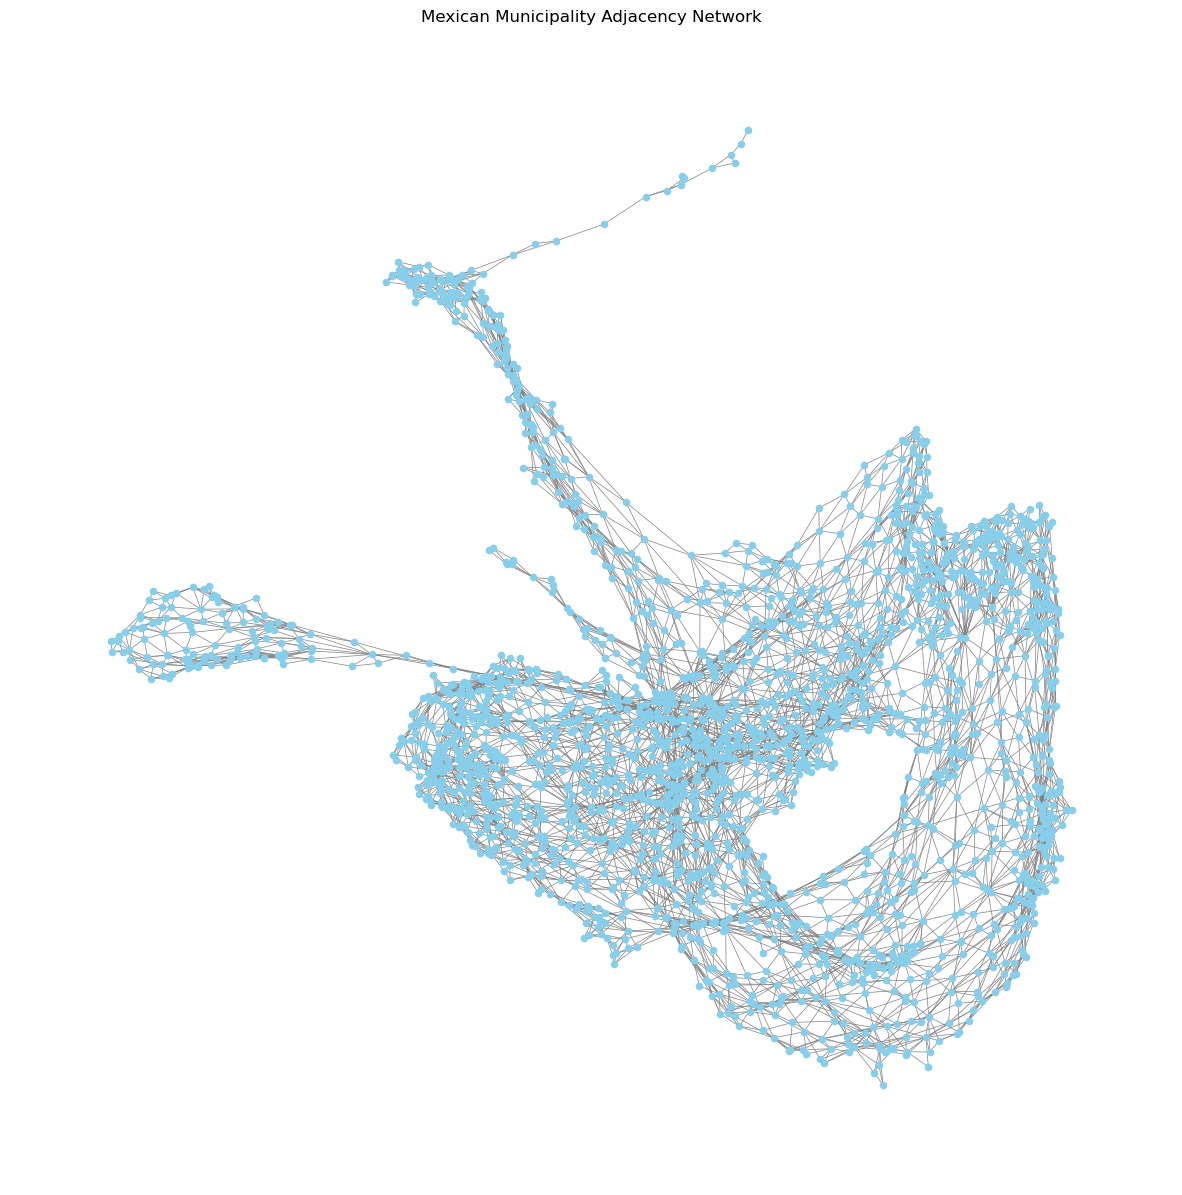

In [5]:

# Create network
G = nx.from_pandas_edgelist(
    edge_df,
    source="source",
    target="target"
)

# Plot
plt.figure(figsize=(15, 15))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos,
    node_size=20,
    node_color="skyblue",
    edge_color="gray",
    width=0.5,
    with_labels=False
)

plt.title("Mexican Municipality Adjacency Network")
plt.axis("off")
plt.show()

In [6]:
list(G.nodes())[:5]


[9012, 9013, 15101, 15062, 15043]

In [7]:


# for year in range(1990, 2011):

#     active_munis = set(
#         df_Zetas.loc[
#             (df_Zetas["Year"] == year) &
#             (df_Zetas["Zetas"] == 1),
#             "Code"
#         ])
#     nx.set_node_attributes(
#     G,
#     {n: int(n in active_munis) for n in G.nodes()},
#     year
# )





In [8]:
# for year in range(1990, 2011):
#     active_munis = set(
#         df_Zetas.loc[
#             (df_Zetas["Year"] == year) &
#             (df_Zetas["Zetas"] == 1),
#             "Code"
#         ]
#     )

#     print(year, len(active_munis))

In [9]:
# G.nodes[9012]

In [10]:
# for year in range(1990, 2011):



#     node_colors = [
#         "red" if G.nodes[n][year] == 1 else "blue"
#         for n in G.nodes()
#     ]
#     node_sizes = [
#         25 if G.nodes[n][year] == 1 else 7
#         for n in G.nodes()
#     ]

#     plt.figure(figsize=(12,12))
#     nx.draw(
#         G,
#         pos,
#         node_color=node_colors,
#         node_size=node_sizes,
#         edge_color="gray",
#         width=0.5,
#         alpha=0.7
#     )

#     plt.title(f"Zetas Presence ({year})")
#     plt.axis("off")
#     plt.show()

In [11]:
# fig, axes = plt.subplots(7, 3, figsize=(15, 30))
# axes = axes.flatten()

# for i, year in enumerate(range(1990, 2011)):

#     node_colors = [
#         "red" if G.nodes[n][year] == 1 else "blue"
#         for n in G.nodes()
#     ]

#     node_sizes = [
#         7 if G.nodes[n][year] == 1 else 1
#         for n in G.nodes()
#     ]

#     nx.draw(
#         G,
#         pos,
#         ax=axes[i],
#         node_color=node_colors,
#         node_size=node_sizes,
#         edge_color="lightgray",
#         width=0.5,
#         alpha=0.4,
#         with_labels=False
#     )

#     axes[i].set_title(year)
#     axes[i].axis("off")

# plt.tight_layout()
# plt.show()

# Machine learning

In [18]:
## for 4 cartels:

df_all = df[['Code', 'Year', 'Beltran_Leyva', 'Beltran_Leyva_Family',
       'Familia', 'Golfo', 'Juarez', 'Sinaloa', 'Sinaloa_Family', 'Tijuana',
       'Zetas', 'Otros']]

G_all = nx.from_pandas_edgelist(
    edge_df,
    source="source",
    target="target"
)

families = ['Beltran_Leyva', 'Beltran_Leyva_Family',
       'Familia', 'Golfo', 'Juarez', 'Sinaloa', 'Sinaloa_Family', 'Tijuana',
       'Zetas', 'Otros']


for year in range(1990, 2011):
    for municipality in G_all.nodes():

        family_presence = {
            family: int(
                municipality in set(
                    df_all.loc[
                        (df_all["Year"] == year) &
                        (df_all[family] == 1),
                        "Code"
                    ]
                )
            )
            for family in families
        }

        family_presence["total_families"] = sum(family_presence.values())

        G_all.nodes[municipality][year] = family_presence


In [ ]:
municipality_chosen = 9012
year_chosen = 2005
G_all.nodes[municipality_chosen][year_chosen]

{'Zetas': 1, 'Sinaloa': 0, 'Otros': 0, 'Familia': 0, 'total_families': 1}

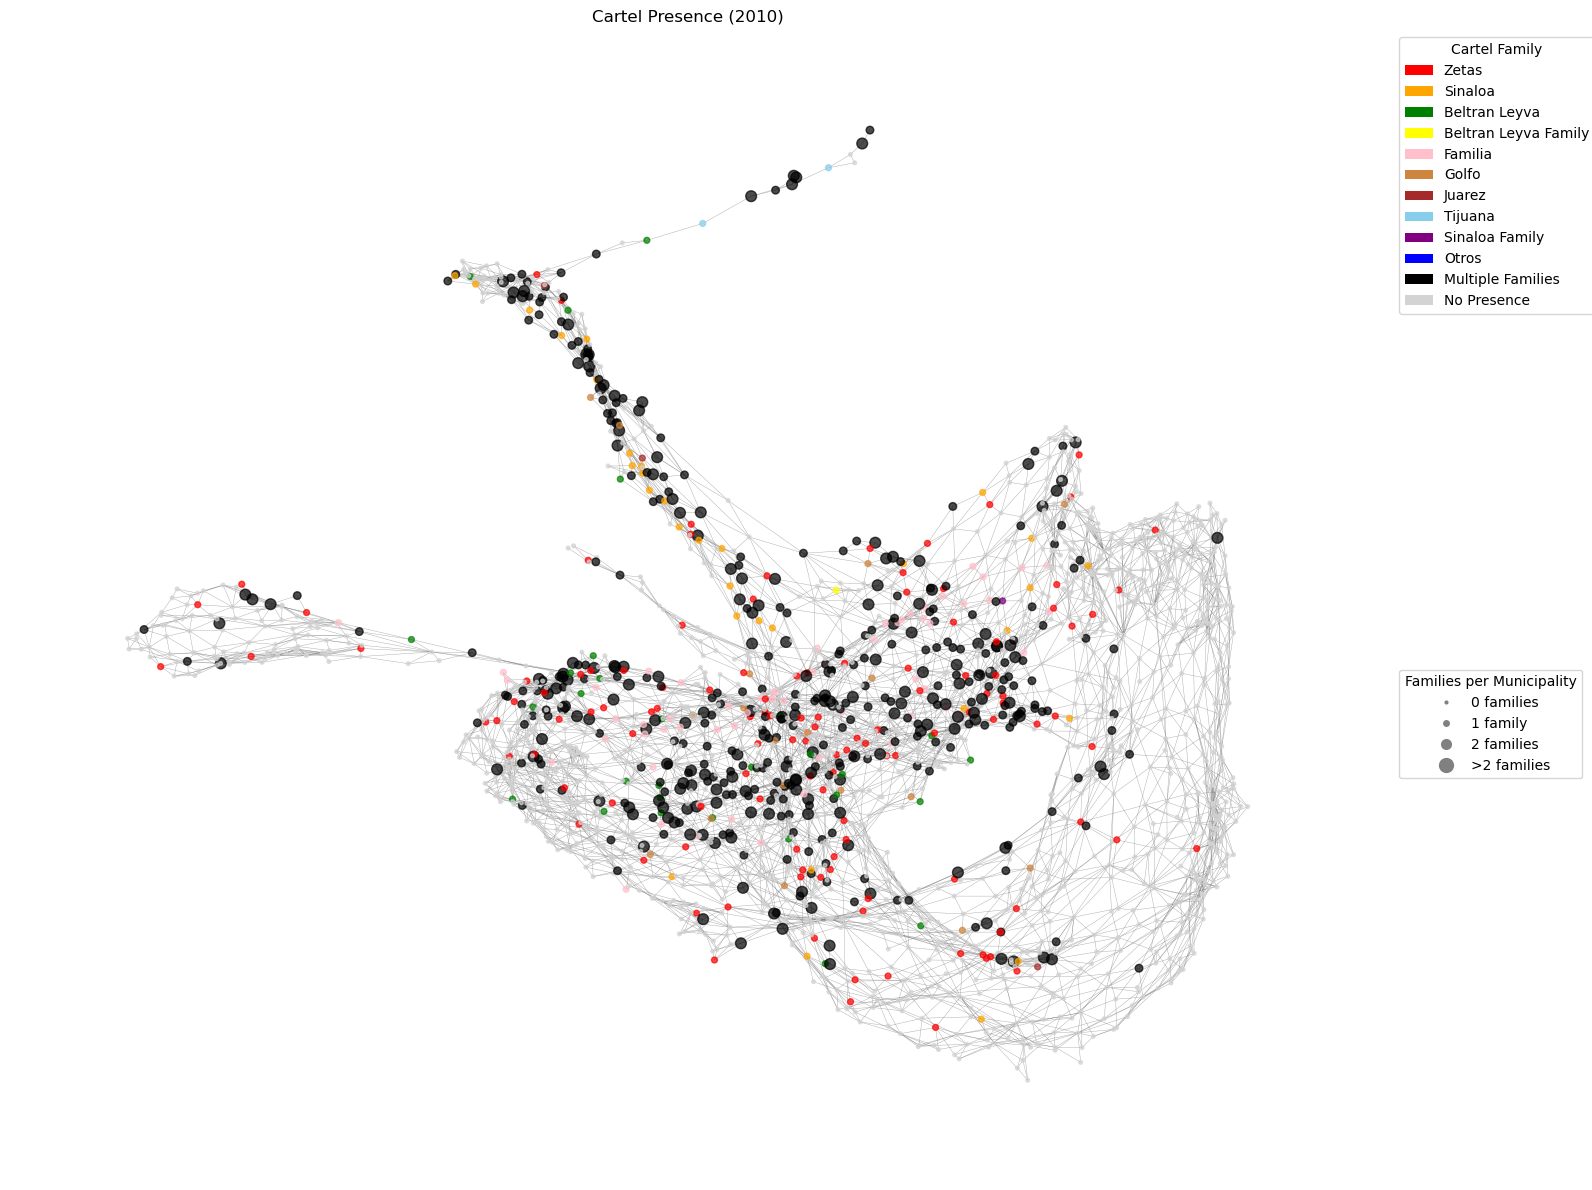

In [26]:

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

year = 2010

# Node colors
node_colors = [
    'black' if G_all.nodes[n][year]['total_families'] > 1 else
    'red' if G_all.nodes[n][year]['Zetas'] == 1 else
    'orange' if G_all.nodes[n][year]['Sinaloa'] == 1 else
    'green' if G_all.nodes[n][year]['Beltran_Leyva'] == 1 else
    'yellow' if G_all.nodes[n][year]['Beltran_Leyva_Family'] == 1 else
    'pink' if G_all.nodes[n][year]['Familia'] == 1 else
    'peru' if G_all.nodes[n][year]['Golfo'] == 1 else
    'brown' if G_all.nodes[n][year]['Juarez'] == 1 else
    'skyblue' if G_all.nodes[n][year]['Tijuana'] == 1 else
    'purple' if G_all.nodes[n][year]['Sinaloa_Family'] == 1 else
    'blue' if G_all.nodes[n][year]['Otros'] == 1 else
    'lightgray'
    for n in G_all.nodes()
]

# Node sizes
node_sizes = [
    60 if G_all.nodes[n][year]['total_families'] > 2 else
    30 if G_all.nodes[n][year]['total_families'] == 2 else
    18 if G_all.nodes[n][year]['total_families'] == 1 else
    7
    for n in G_all.nodes()
]

# Color legend
family_legend = [
    Patch(facecolor='red', label='Zetas'),
    Patch(facecolor='orange', label='Sinaloa'),
    Patch(facecolor='green', label='Beltran Leyva'),
    Patch(facecolor='yellow', label='Beltran Leyva Family'),
    Patch(facecolor='pink', label='Familia'),
    Patch(facecolor='peru', label='Golfo'),
    Patch(facecolor='brown', label='Juarez'),
    Patch(facecolor='skyblue', label='Tijuana'),
    Patch(facecolor='purple', label='Sinaloa Family'),
    Patch(facecolor='blue', label='Otros'),
    Patch(facecolor='black', label='Multiple Families'),
    Patch(facecolor='lightgray', label='No Presence')
]

# Size legend
size_legend = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='gray',
        markersize=4,
        label='0 families'
    ),
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='gray',
        markersize=6,
        label='1 family'
    ),
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='gray',
        markersize=9,
        label='2 families'
    ),
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='gray',
        markersize=12,
        label='>2 families'
    )
]

# Plot
fig, ax = plt.subplots(figsize=(16, 12))

nx.draw(
    G_all,
    pos,
    node_color=node_colors,
    node_size=node_sizes,
    edge_color='gray',
    width=0.3,
    alpha=0.7,
    ax=ax
)

# First legend (colors)
legend1 = ax.legend(
    handles=family_legend,
    title='Cartel Family',
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0)
)
ax.add_artist(legend1)

# Second legend (sizes)
ax.legend(
    handles=size_legend,
    title='Families per Municipality',
    loc='upper left',
    bbox_to_anchor=(1.02, 0.45)
)

plt.title(f'Cartel Presence ({year})')
plt.axis('off')
plt.tight_layout()
plt.show()

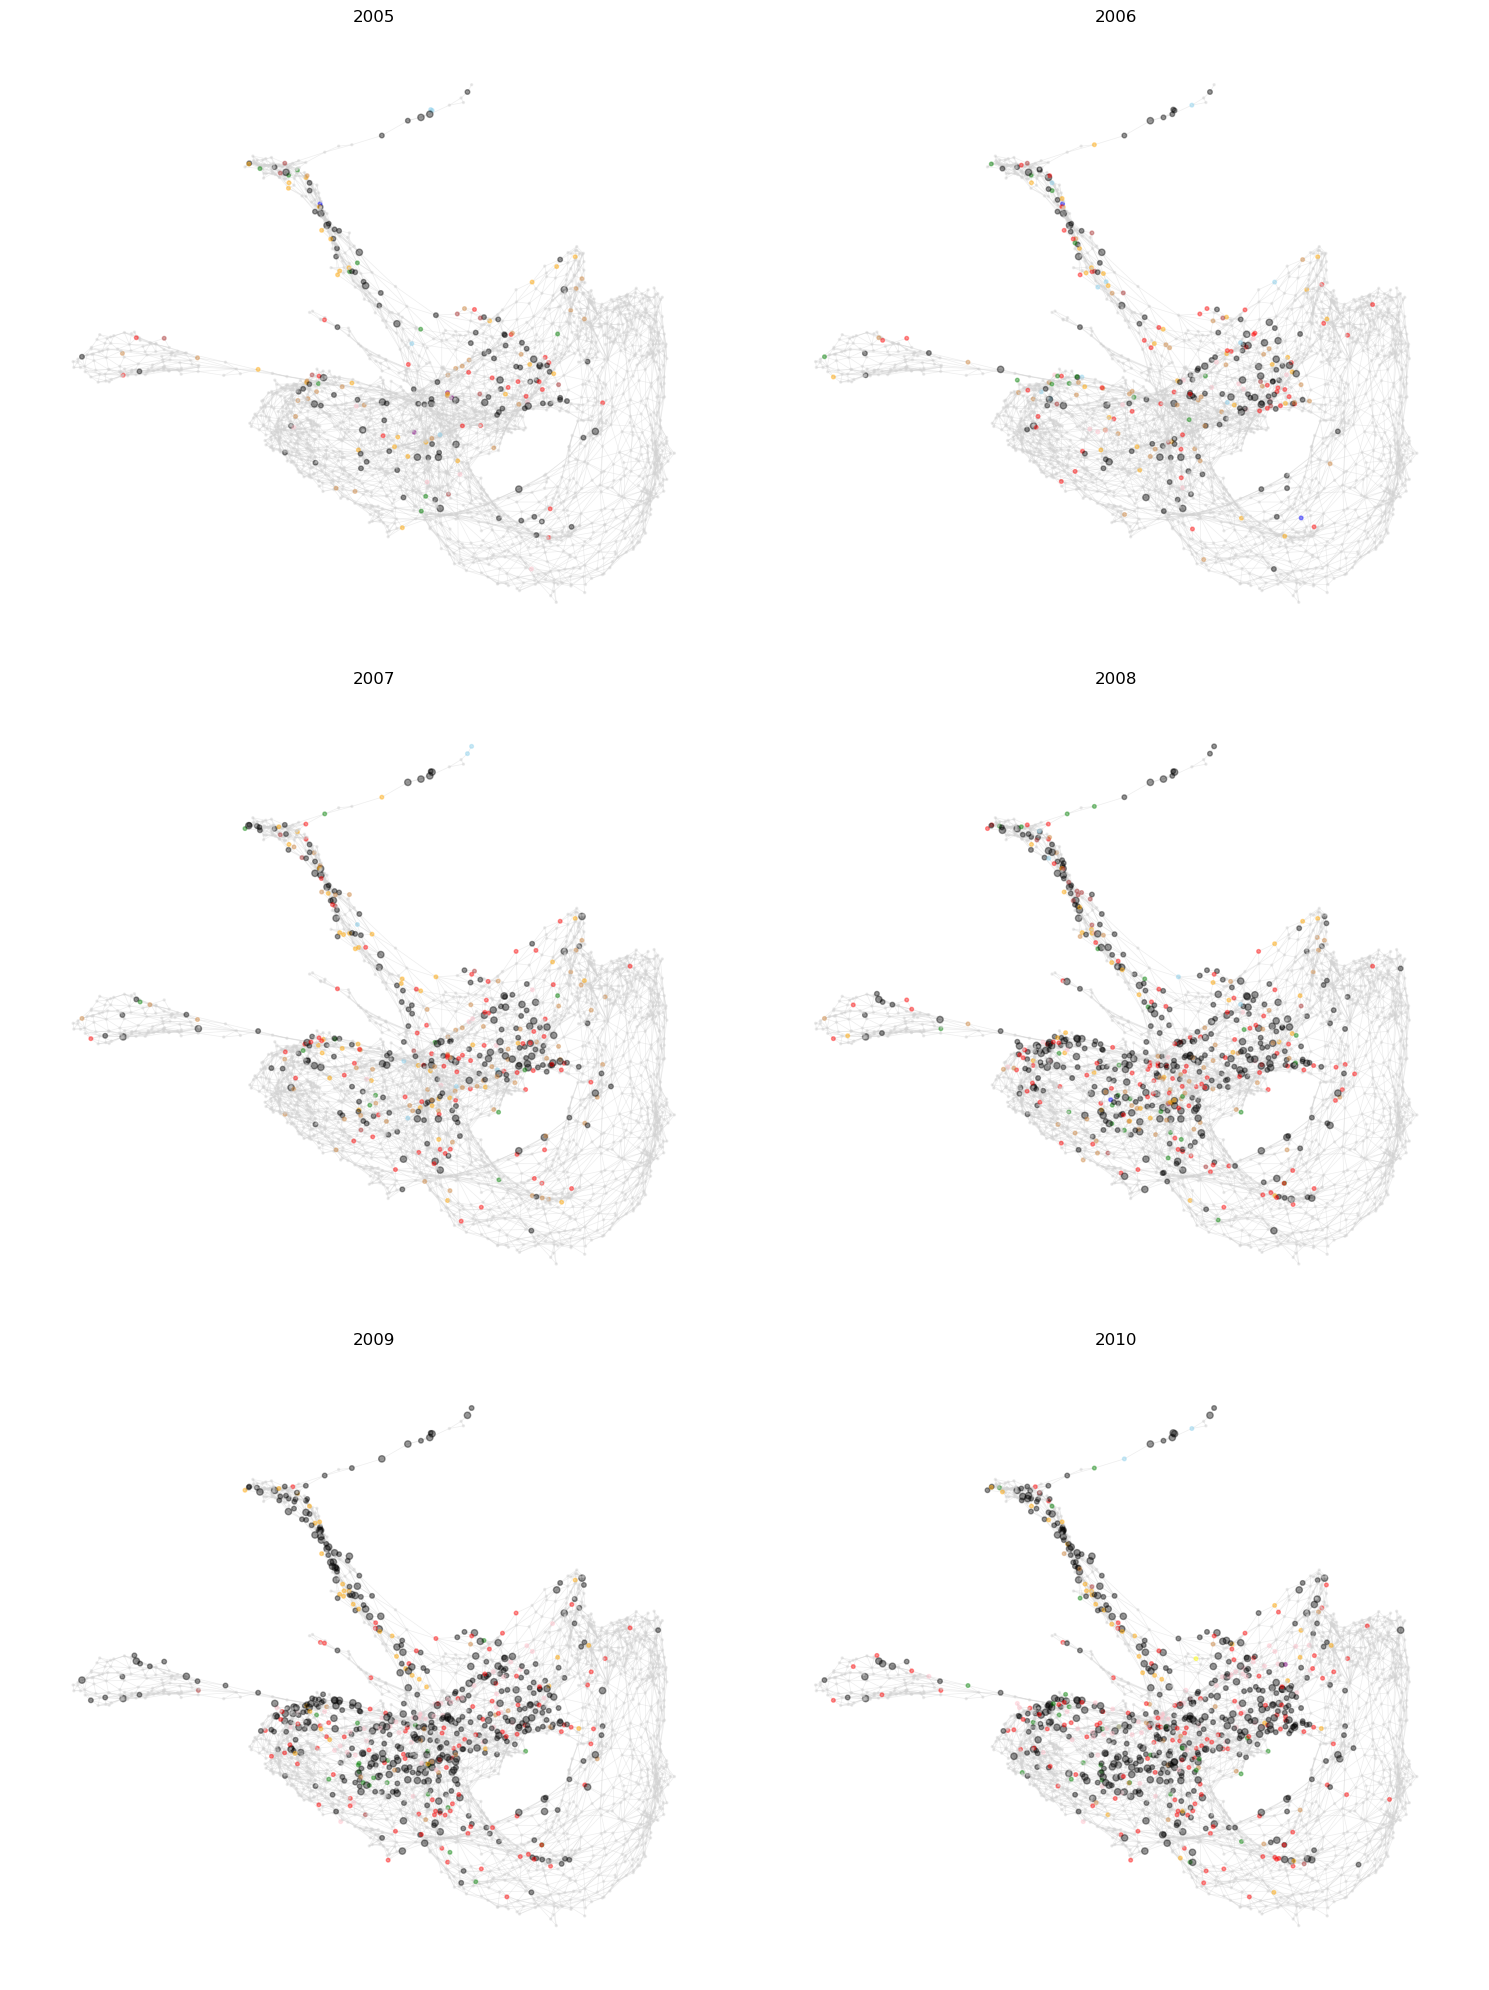

In [30]:
fig, axes = plt.subplots(3, 2, figsize=(15, 20))
axes = axes.flatten()

for i, year in enumerate(range(2005, 2011)):

    node_colors = [
        'black' if G_all.nodes[n][year]['total_families'] > 1 else
        'red' if G_all.nodes[n][year]['Zetas'] == 1 else
        'orange' if G_all.nodes[n][year]['Sinaloa'] == 1 else
        'green' if G_all.nodes[n][year]['Beltran_Leyva'] == 1 else
        'yellow' if G_all.nodes[n][year]['Beltran_Leyva_Family'] == 1 else
        'pink' if G_all.nodes[n][year]['Familia'] == 1 else
        'peru' if G_all.nodes[n][year]['Golfo'] == 1 else
        'brown' if G_all.nodes[n][year]['Juarez'] == 1 else
        'skyblue' if G_all.nodes[n][year]['Tijuana'] == 1 else
        'purple' if G_all.nodes[n][year]['Sinaloa_Family'] == 1 else
        'blue' if G_all.nodes[n][year]['Otros'] == 1 else
        'lightgray'
        for n in G_all.nodes()
    ]
    node_sizes = [
        21 if G_all.nodes[n][year]['total_families'] > 2 else
        11 if G_all.nodes[n][year]['total_families'] == 2 else
        7 if G_all.nodes[n][year]['total_families'] == 1 else 2
    
        for n in G_all.nodes()
    ]

    nx.draw(
        G,
        pos,
        ax=axes[i],
        node_color=node_colors,
        node_size=node_sizes,
        edge_color="lightgray",
        width=0.5,
        alpha=0.4,
        with_labels=False
    )

    axes[i].set_title(year)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Features to take into account:

1) direct neighbours of infected points
2) 2nd direct neighbours of infected points